# Facial Age Estimation with ResNet50

**Computer Vision | Deep Learning | Transfer Learning**

This project estimates a person’s age from facial images using a pretrained ResNet50 regression model. The notebook covers dataset exploration, preprocessing, model training, and evaluation. Original execution outputs are retained for reproducibility and review.

## 1. Environment Setup


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from tensorflow.keras.preprocessing.image import ImageDataGenerator
from PIL import Image

import os

%matplotlib inline

## 2. Dataset Access


The dataset contains approximately 7,600 face images in `final_files/` and a `labels.csv` file with two columns: `file_name` and `real_age`.

Download `faces.zip` from the [dataset folder](https://drive.google.com/drive/folders/1ik4AkZcb-cG_Ga-Hu5rN1GianXFmkLZ8) and upload it to your own Google Drive. By default, the following cell reads `/content/drive/MyDrive/faces.zip`; update `DRIVE_ZIP_PATH` if you store it elsewhere. In Google Colab, mount permission is required. Extraction is skipped if the dataset has already been extracted in the current session.

The loader also supports an existing local `/datasets/faces/` directory. A GPU runtime is recommended for training.


In [2]:
import os
import zipfile
from pathlib import Path

import pandas as pd

# Update this path if faces.zip is stored in a different Google Drive folder.
DRIVE_ZIP_PATH = Path('/content/drive/MyDrive/faces.zip')
LOCAL_DATA_DIR = Path('/datasets/faces')
COLAB_EXTRACT_DIR = Path('/content/faces_dataset')

if (LOCAL_DATA_DIR / 'labels.csv').is_file():
    path = str(LOCAL_DATA_DIR) + os.sep
else:
    try:
        from google.colab import drive
    except ImportError as exc:
        raise RuntimeError('Run this notebook in Google Colab or provide /datasets/faces/.') from exc

    drive.mount('/content/drive')
    if not DRIVE_ZIP_PATH.is_file():
        raise FileNotFoundError(f'Dataset archive not found: {DRIVE_ZIP_PATH}')

    COLAB_EXTRACT_DIR.mkdir(parents=True, exist_ok=True)
    matches = list(COLAB_EXTRACT_DIR.rglob('labels.csv'))
    if not matches:
        with zipfile.ZipFile(DRIVE_ZIP_PATH) as archive:
            archive.extractall(COLAB_EXTRACT_DIR)
        matches = list(COLAB_EXTRACT_DIR.rglob('labels.csv'))
    if not matches:
        raise FileNotFoundError('labels.csv was not found inside faces.zip')
    path = str(matches[0].parent) + os.sep

print(f'Dataset directory: {path}')


Mounted at /content/drive


## 3. Exploratory Data Analysis (EDA)


Dimensões do conjunto de dados: (7591, 2)


,file_name,real_age
0,000000.jpg,4
1,000001.jpg,18
2,000002.jpg,80
3,000003.jpg,50
4,000004.jpg,17


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7591 entries, 0 to 7590
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   file_name  7591 non-null   object
 1   real_age   7591 non-null   int64 
dtypes: int64(1), object(1)
memory usage: 118.7+ KB


,real_age
count,7591.000000
mean,31.201159
std,17.145060
min,1.000000
25%,20.000000
50%,29.000000
75%,41.000000
max,100.000000



Valores ausentes:
file_name    0
real_age     0
dtype: int64


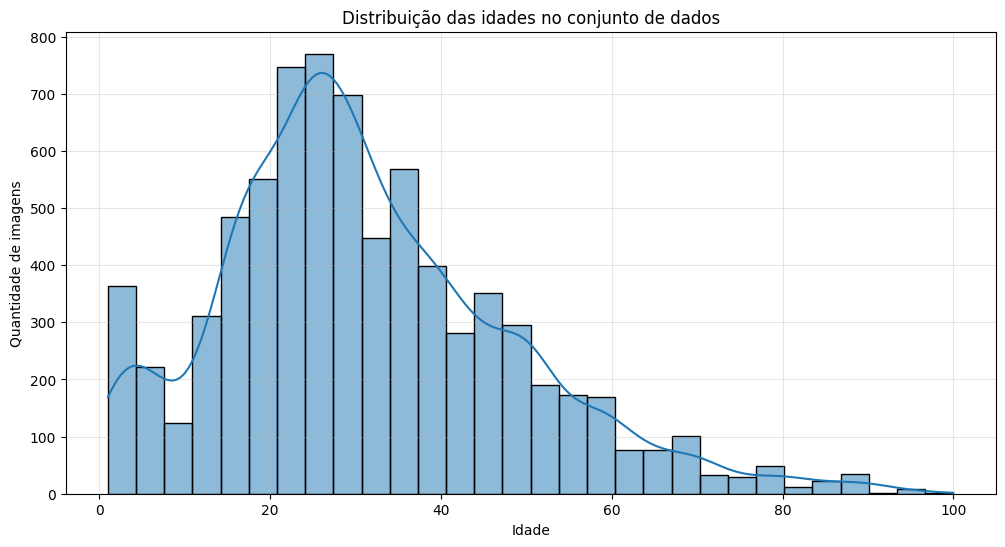

In [3]:
# Load image labels.
labels = pd.read_csv(path + 'labels.csv')

# Inspect dataset dimensions and sample records.
print('Dataset dimensions:', labels.shape)
display(labels.head())

# Review schema, age statistics, and missing values.
labels.info()
display(labels['real_age'].describe())
print('\nMissing values:')
print(labels.isnull().sum())

# Plot the age distribution.
plt.figure(figsize=(12, 6))
sns.histplot(labels['real_age'], bins=30, kde=True)
plt.title('Age Distribution in the Dataset')
plt.xlabel('Age')
plt.ylabel('Number of Images')
plt.grid(alpha=0.3)
plt.show()


### EDA Findings


The dataset contains **7,591 records** with two columns: `file_name` (image filename) and `real_age` (ground-truth age). No missing values were identified. Ages range from **1 to 100 years**, with a mean of approximately **31.2** and a median of **29**.

Most images represent people aged **20–40**, while older age groups are less represented. This imbalance may increase prediction errors for less frequent ages. Transfer learning with a pretrained ResNet50 is used to make efficient use of the available images.


## 4. Model Architecture and Data Pipeline


The pipeline uses `ImageDataGenerator` with ResNet50 preprocessing and an 80/20 training-validation split. The pretrained ResNet50 backbone is adapted for age regression.


In [5]:
import pandas as pd

import tensorflow as tf

from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications.resnet import ResNet50, preprocess_input
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import GlobalAveragePooling2D, Dense, Dropout, Flatten
from tensorflow.keras.optimizers import Adam

In [6]:

def load_data(path, subset='training'):
    labels = pd.read_csv(path + 'labels.csv')

    data_datagen = ImageDataGenerator(
        preprocessing_function=preprocess_input,
        validation_split=0.2
    )

    data_gen_flow = data_datagen.flow_from_dataframe(
        dataframe=labels,
        directory=path + 'final_files/',
        x_col='file_name',
        y_col='real_age',
        target_size=(224, 224),
        batch_size=16,
        class_mode='raw',
        subset=subset,
        seed=12345
    )

    return data_gen_flow

In [7]:
def create_model(input_shape):

    backbone = ResNet50(
        weights='imagenet',
        input_shape=input_shape,
        include_top=False
    )

    model = Sequential()
    model.add(backbone)
    model.add(GlobalAveragePooling2D())
    model.add(Dense(1, activation='relu'))

    optimizer = Adam(learning_rate=0.0001)

    model.compile(
        optimizer=optimizer,
        loss='mse',
        metrics=['mae']
    )

    return model

In [8]:

def train_model(model, train_data, test_data, batch_size=None, epochs=5):

    model.fit(
        train_data,
        validation_data=test_data,
        epochs=epochs,
        verbose=2
    )

    return model

## 5. Training and Evaluation


For faster training, run the notebook in **Google Colab with a GPU runtime**. Execute the dataset-loading cell after connecting to the runtime, then run the model-training cell below. The saved outputs in this notebook reflect the original run and are not recomputed by this edit.


### Model Results


The following cell trains the model for five epochs and evaluates mean absolute error (MAE) on the validation split.


In [9]:
# Load training and validation data.
train_data = load_data(path, subset='training')
test_data = load_data(path, subset='validation')

# Initialize the ResNet50 regression model.
model = create_model(input_shape=(224, 224, 3))

# Train for five epochs.
model = train_model(
    model,
    train_data,
    test_data,
    epochs=5
)

# Evaluate on the validation set.
loss, mae = model.evaluate(test_data, verbose=1)

print(f'Mean Absolute Error (MAE): {mae:.2f} years')


Found 6073 validated image filenames.
Found 1518 validated image filenames.
94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/5
380/380 - 211s - 556ms/step - loss: 208.5051 - mae: 10.4482 - val_loss: 140.3226 - val_mae: 8.6675
Epoch 2/5
380/380 - 91s - 240ms/step - loss: 79.8310 - mae: 6.7335 - val_loss: 114.4778 - val_mae: 8.0582
Epoch 3/5
380/380 - 71s - 188ms/step - loss: 52.0203 - mae: 5.5349 - val_loss: 102.0160 - val_mae: 7.5319
Epoch 4/5
380/380 - 71s - 187ms/step - loss: 34.3643 - mae: 4.4673 - val_loss: 95.0924 - val_mae: 7.2153
Epoch 5/5
380/380 - 70s - 185ms/step - loss: 23.7616 - mae: 3.7508 - val_loss: 68.1022 - val_mae: 6.1838
95/95 ━━━━━━━━━━━━━━━━━━━━ 8s 86ms/step - loss: 68.1022 - mae: 6.1838
Erro Absoluto Médio (MAE): 6.18 anos


This project developed a facial age estimation model using **ResNet50 pretrained on ImageNet** and adapted for a regression task.

### Dataset and preprocessing

The dataset contains **7,591 facial images**, with ages ranging from **1 to 100 years** and an average age of approximately **31.2 years**. No missing labels were found. The age distribution is concentrated between 20 and 40 years, which may reduce generalization to underrepresented age groups.

### Training and performance

The dataset was divided into **6,073 training images (80%)** and **1,518 validation images (20%)**. The model uses a single-neuron ReLU output layer, Adam optimizer with a learning rate of **0.0001**, and mean squared error (MSE) loss. Training ran for **five epochs**.

Validation MAE improved across epochs:

| Epoch | Validation MAE (years) |
|---|---:|
| 1 | 8.67 |
| 2 | 8.06 |
| 3 | 7.53 |
| 4 | 7.22 |
| 5 | **6.18** |

The final reported **validation MAE was 6.18 years**, below the original project target of 8 years.

### Limitations and next steps

The gap between training MAE (**3.75 years**) and validation MAE (**6.18 years**) suggests some overfitting. The uneven age distribution may also contribute to higher errors for underrepresented ages. Potential improvements include age-stratified error analysis, stronger augmentation, and regularization. These improvements have not been implemented or evaluated in this notebook.
